In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "2"

# Кластеризация

**Цель работы:**

Изучение алгоритмов и методов кластеризации на практике.

### Часть 1 
#### 1.1    Генерация и предобработка набора данных
Функция создаёт DataFrame с 3 группами по n объектов каждая и признаками x и y.

In [2]:
import numpy as np
import pandas as pd

def make_data(n, seed):
    np.random.seed(seed)
    shift_matrix = np.array([[3, 3],
                             [6, 9],
                             [9, 3]])
    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)    # оси 1 и 2 поменяны местами: группа - объект - координата
    data = data.reshape((-1, 2))    # вместо двух осей - одна ось длиной в 3n точек 
    data *= np.array([[20, 0.5]])
    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]},
                      columns=['x', 'y'])
    df = df.sample(frac=1.0)    # перемешивание групп
    return df

`shift_matrix` это двумерный массив формы (3, 2). `randn` генерирует трехмерную выборку из стандартного нормального распределения (современный подход через `standart_normal`) размером (3, 2, n). Далее полученный "шум" вокруг нуля сдвигается за счёт прибавления матрицы сдвига `shift_matrix`, при сложении NumPy «растягивает» этот массив по последней оси (по n). В результате внутри первой группы к первой координате прибавляется 3, ко второй тоже 3; во второй группе соответственно +6, +9; в третьей +9, +3.   
Метод `df.sample(frac=1.0)` возвращает случайную выборку строк DataFrame. При этом параметр `frac=1.0` означает долю, в данном случае 100 % строк.   

In [3]:
df = make_data(100, 15)
display(df)
# df.describe()

,x,y
43,46.649670,1.300508
127,114.602554,4.582664
200,213.764482,0.699972
107,129.418887,3.930599
68,67.100921,1.558457
...,...,...
185,86.340169,4.453972
111,143.422477,4.492222
287,175.091372,2.246279
254,172.469148,1.431849


Перед обучением стандартизация данных **обязательна**, поэтому используется отдельная структура StandardScaler модуля sklearn.preprocessing:

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() # создание объекта класса Scaler
scaler.fit(df) # обучение стандартизатора - вычисление mean и std
print(scaler.mean_)   # массив средних по каждому столбцу
print(scaler.scale_)
df_scaled = scaler.transform(df) # преобразование данных 
pd.DataFrame(df_scaled).describe()

[120.13466692   2.46690399]
[53.5790133   1.48142831]


,0,1
count,3.000000e+02,3.000000e+02
mean,4.144833e-17,1.065814e-16
std,1.001671e+00,1.001671e+00
min,-2.134585e+00,-1.822588e+00
25%,-9.006507e-01,-7.567074e-01
50%,7.775064e-03,-4.751663e-01
75%,8.643784e-01,1.097240e+00
max,1.911644e+00,2.274045e+00


Значение `mean ≈ 0`, а `std ≈ 1`, значит стандартизаци прошла успешно и оба признака **сопоставимы по масштабу**. 

#### 1.2    Кластеризация методом k-means
Алгоритм K-средних является одним из наиболее простых и широко используемых методов кластеризации. Он основывается на идее разделения данных на K кластеров, где K — заданное число кластеров. Этот метод чувствителен к числу кластеров и основан на предположении, что *число групп известно заранее*.   
Итерационно алгоритм перемещает центроиды кластеров в такие точки пространства данных, которые минимизируют суммарное расстояние от всех точек данных до центроидов. Этот процесс продолжается до тех пор, пока центроиды больше не меняются, или достигнута максимальная заданная точность.   
Для реализации данного алгоритма в Python используется `Kmeans`. 

In [5]:
from sklearn.cluster import KMeans
import os

os.environ["OMP_NUM_THREADS"] = "2"

k_means = KMeans(n_clusters=3, random_state=15)  # random_state для воспроизводимости деления на кластеры
clusters = k_means.fit_predict(df_scaled)          # формирование вектора с метками кластеров

Теперь для каждой строки из df_scaled указан номер кластера: 0, 1 или 2. 

In [6]:
# метки кластеров
print(clusters)                 

[0 1 2 1 0 1 0 1 1 0 1 2 1 1 0 2 0 2 1 2 1 0 0 2 1 1 0 0 1 2 1 2 2 2 0 0 2
 2 0 1 1 1 0 2 2 2 0 2 0 0 1 0 1 1 2 2 2 2 0 1 0 0 1 2 2 1 2 2 0 0 1 2 1 0
 1 0 2 2 0 0 0 1 0 1 0 1 2 2 1 2 1 0 1 1 1 0 2 0 0 1 1 2 0 2 0 0 2 1 0 1 0
 1 1 2 1 2 1 1 0 1 0 0 2 2 2 1 2 1 1 1 1 1 1 1 0 0 1 1 1 1 1 2 0 0 0 1 0 2
 2 2 2 0 2 1 0 2 2 1 0 2 2 2 2 1 2 2 2 0 1 0 2 2 2 2 2 2 1 1 2 2 1 1 0 1 2
 1 1 0 0 0 0 2 0 2 2 2 0 0 2 0 0 2 2 0 1 2 2 0 0 1 1 2 0 2 0 0 1 2 0 2 2 1
 1 1 0 0 0 2 1 2 1 1 1 2 2 1 0 2 0 0 1 0 1 0 0 1 2 0 1 1 2 2 1 1 0 1 1 0 0
 1 2 2 1 0 0 1 0 0 2 2 0 2 1 2 2 1 2 0 1 2 2 2 0 2 0 0 0 0 0 0 0 0 1 1 0 1
 1 2 2 0]


Для визуализации кластеров используется диаграмма рассеивания (scatter). 

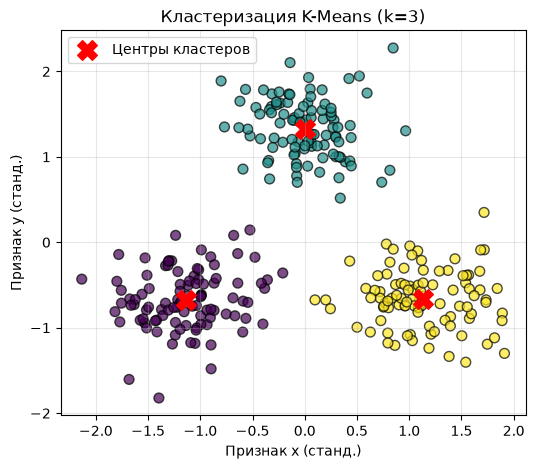

In [7]:
import matplotlib.pyplot as plt

# диаграмма по стандартизованным данным, метка кластера -> цвет
plt.figure(figsize=(6, 5))
plt.scatter(df_scaled[:, 0], df_scaled[:, 1], 
            c=clusters, cmap='viridis', s=50, alpha=0.7, edgecolors='k')

# центры кластеров
centers = k_means.cluster_centers_    # тоже numpy-массив формы (k, 2)

# первые 2 аргумента - одномерные массивы одинаковой длины
plt.scatter(centers[:, 0], centers[:, 1], 
            c='red', s=200, marker='X', label='Центры кластеров')

plt.xlabel('Признак x (станд.)')
plt.ylabel('Признак y (станд.)')
plt.title('Кластеризация K-Means (k=3)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Точки, принадлежащие одному кластеру, окрашены в один цвет и располагаются около соответствующих центров (красных крестиков). Визуально наблюдается три хорошо разделённых группы, что свидетельствует о корректной работе алгоритма k-means при k=3.

#### 1.3    Оценка качества кластеризации 
Одной из внутренних метрик (нет заранее известного разделения на классы) качества является **коэффициент силуэта**. Он принимает значения в диапазоне (-1; 1) и показывает, насколько объект похож на другие объекты своего кластера.    
Силуэт объекта $i$ вычисляется по формуле:$$S_i = \frac{b_i - a_i}{\max(a_i, b_i)},$$где
$a_i$ — среднее расстояние между объектом $i$ и другими объектами того же кластера;
$b_i$ — наименьшее среднее расстояние между объектом $i$ и объектами всех других кластеров.   
Интерпретация:   
- если $S_i > 0$, то в среднем точки своего кластера ближе, чем точки из других кластеров ($b_i > a_i$);
- если $S_i < 0$, то ситуация обратная — объект ближе к чужому кластеру, чем к своему;
- значение, близкое к 1, означает хорошую кластеризацию объекта;
- значение, близкое к −1, означает неудачную кластеризацию объекта.
  
Силуэт выборки — средняя величина силуэта объектов данной выборки. Он показывает общее качество кластеризации и также лежит в диапазоне от −1 до +1. Значение около 0 указывает на перекрывающиеся кластеры.

In [8]:
from sklearn.metrics import silhouette_score

sil_3 = silhouette_score(df_scaled, clusters)
print(f"Силуэт для k=3: {sil_3:.4f}")

Силуэт для k=3: 0.7043


Полученное значение коэффициента силуэта (≈ 0.7) заметно больше 0 и достаточно близко к 1, то есть в среднем объекты находятся ближе к точкам своего кластера, чем к точкам других кластеров ($a_i < b_i$). Можно сказать, что полученные кластеры компактны и хорошо разделены.   
#### 1.4 Обучение модели для k=2 и k=4

Силуэт для k=2: 0.4716
Силуэт для k=4: 0.5578


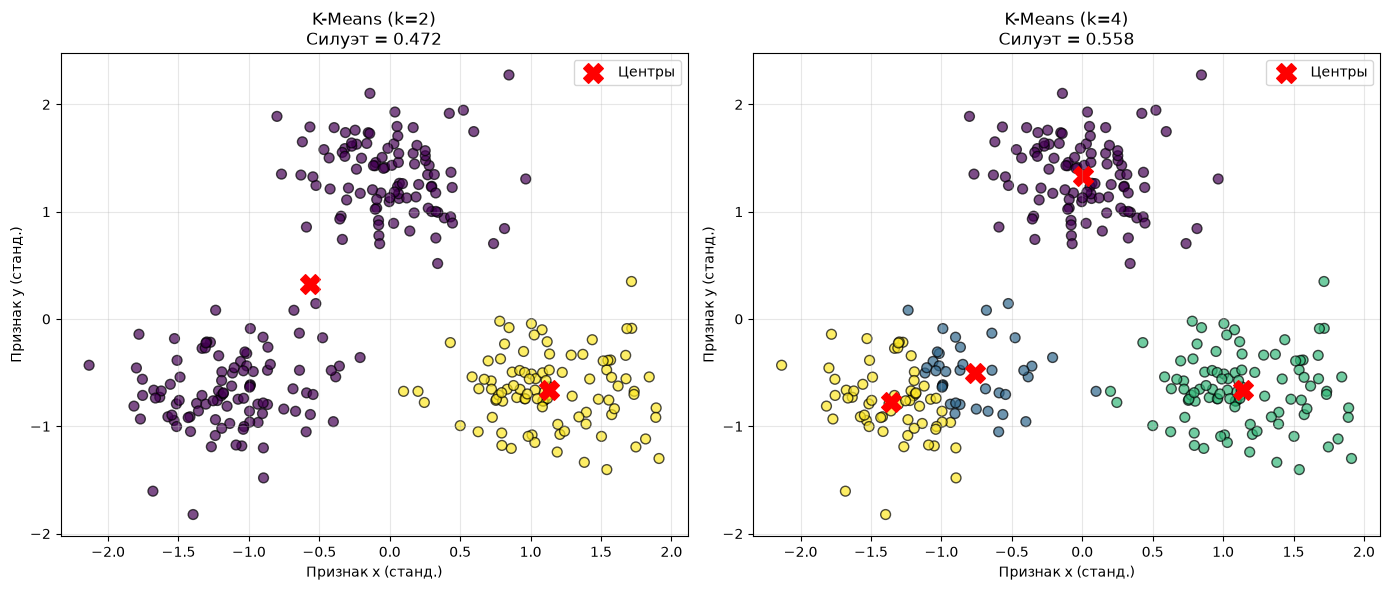

In [9]:
k_means_2 = KMeans(n_clusters=2, random_state=10)  
clusters_2 = k_means_2.fit_predict(df_scaled)    
sil_2 = silhouette_score(df_scaled, clusters_2)

k_means_4 = KMeans(n_clusters=4, random_state=20)  
clusters_4 = k_means_4.fit_predict(df_scaled)    
sil_4 = silhouette_score(df_scaled, clusters_4)
print(f"Силуэт для k=2: {sil_2:.4f}")
print(f"Силуэт для k=4: {sil_4:.4f}")

#___________визуализация___________
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# График для k=2
axes[0].scatter(df_scaled[:, 0], df_scaled[:, 1],
                c=clusters_2, cmap='viridis', s=50, alpha=0.7, edgecolors='k')
centers_2 = k_means_2.cluster_centers_
axes[0].scatter(centers_2[:, 0], centers_2[:, 1],
                c='red', s=200, marker='X', label='Центры')
axes[0].set_title(f'K-Means (k=2)\nСилуэт = {sil_2:.3f}')
axes[0].set_xlabel('Признак x (станд.)')
axes[0].set_ylabel('Признак y (станд.)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# График для k=4
axes[1].scatter(df_scaled[:, 0], df_scaled[:, 1],
                c=clusters_4, cmap='viridis', s=50, alpha=0.7, edgecolors='k')
centers_4 = k_means_4.cluster_centers_
axes[1].scatter(centers_4[:, 0], centers_4[:, 1],
                c='red', s=200, marker='X', label='Центры')
axes[1].set_title(f'K-Means (k=4)\nСилуэт = {sil_4:.3f}')
axes[1].set_xlabel('Признак x (станд.)')
axes[1].set_ylabel('Признак y (станд.)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Все значения метрики положительные, то есть в среднем объекты ближе к своему кластеру, чем к чужим. Однако максимальное качество всё же достигается при k = 3.    
**k = 2**   
Фиолетовый кластер объединяет две хорошо различимые группы точек (верхнюю и нижнюю левую). Центр этого кластера оказывается между ними, поэтому внутрикластерные расстояния большие. Жёлтый кластер почти совпадает с одним из кластеров при k=3 и выглядит компактным. В итоге силуэт заметно ниже, чем при правильном числе кластеров.   
**k = 4**   
Один из плотных кластеров (фиолетовый при k=3) искусственно разделён на два. Эти два новых кластера перекрываются и мало отличаются друг от друга по расположению точек. Остальные два кластера совпадают с голубым и желтым кластерами при k=3. Из-за избыточного разбиения качество падает по сравнению с k=3.

#### 1.5 Метод локтя
Наилучшее разбиение получено при k = 3: максимальный коэффициент силуэта (≈ 0.70) и визуально чёткие, компактные и хорошо разделённые кластеры.

При k=2 происходит недоразбиение (две естественные группы объединяются в одну), при k=4 — переразбиение (один естественный кластер делится на два перекрывающихся). Оба случая дают более низкое значение силуэта.

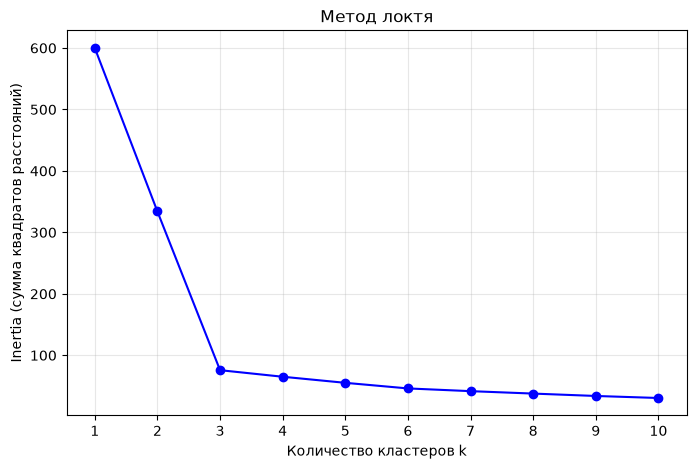

In [10]:
inertias = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=15, n_init=10)
    kmeans.fit(df_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Количество кластеров k')
plt.ylabel('Inertia (сумма квадратов расстояний)')
plt.title('Метод локтя')
plt.grid(True, alpha=0.3)
plt.xticks(K_range)
plt.show()

На графике метода локтя наблюдается характерный излом при k = 3. Дальнейшее увеличение числа кластеров даёт лишь незначительное уменьшение distortion score. Это подтверждает, что оптимальное количество кластеров равно 3, что согласуется с максимальным значением коэффициента силуэта.

### Часть 2

Вариант №1 

Набор данных: датасет medical_diagnosis.csv содержит информацию о болезнях.   
Атрибуты:
- age — возраст пациента (лет), числовой.
- sex — пол: Male / Female, категориальный.
- BMI — индекс массы тела (кг/м²), числовой.
- systolic_bp — систолическое артериальное давление, мм рт. ст., числовой.
- cholesterol_mg_dl — общий холестерин сыворотки, мг/дл, числовой.
- fasting_glucose_mg_dl — глюкоза крови натощак, мг/дл, числовой.
- smoking_status — статус курения: Never / Former / Current, категориальный.
- family_history — наследственность по заболеванию: Yes / No, категориальный.
- activity_level — уровень физической активности: Low / Moderate / High, категориальный.
- symptom_score — суммарная выраженность симптомов (0–10), числовой.
- CRP_mg_L — С-реактивный белок, мг/л (маркер воспаления), числовой.
- WBC_10e9_L — лейкоциты, ×10⁹/л, числовой.
- ECG_result — результат ЭКГ: Normal / ST-T abnormality / LVH, категориальный.
- Disease — целевой класс: 1 — болеет, 0 — не болеет.

In [11]:
df_med = pd.read_csv('medical_diagnosis.csv') # чтение данных из файла
df_med.head()

,age,sex,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,smoking_status,family_history,activity_level,symptom_score,CRP_mg_L,WBC_10e9_L,ECG_result,Disease
0,34,Male,16.8,132.0,196.0,78.0,Current,No,High,0.2,0.58,8.60,Normal,0
1,24,Female,29.2,118.0,182.0,96.0,Current,No,Moderate,3.2,2.72,6.54,Normal,0
2,19,Female,16.5,121.0,268.0,101.0,Current,No,Moderate,3.8,0.18,6.61,Normal,0
3,89,Female,15.4,117.0,136.0,96.0,Never,No,Low,2.6,1.83,5.67,Normal,0
4,66,Male,16.7,82.0,241.0,126.0,Former,No,Moderate,3.5,1.16,2.66,Normal,0


#### 2.1 Чтение и предобработка данных

In [12]:
df_med.info()

<class 'pandas.DataFrame'>
RangeIndex: 3031 entries, 0 to 3030
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    3031 non-null   int64  
 1   sex                    3031 non-null   str    
 2   BMI                    3031 non-null   float64
 3   systolic_bp            3031 non-null   float64
 4   cholesterol_mg_dl      3031 non-null   float64
 5   fasting_glucose_mg_dl  3031 non-null   float64
 6   smoking_status         3031 non-null   str    
 7   family_history         3031 non-null   str    
 8   activity_level         3031 non-null   str    
 9   symptom_score          3031 non-null   float64
 10  CRP_mg_L               3031 non-null   float64
 11  WBC_10e9_L             3031 non-null   float64
 12  ECG_result             3031 non-null   str    
 13  Disease                3031 non-null   int64  
dtypes: float64(7), int64(2), str(5)
memory usage: 408.9 KB


Всего таблица содержит 3030 строк, пропущенных значений нет. Типы данных сопоставимы с описанием датасета.

In [13]:
print(df_med.duplicated().sum()) # подсчет количества дубликатов

1


In [14]:
df_med = df_med.drop_duplicates().reset_index(drop=True)
print(df_med.duplicated().sum()) # подсчет количества дубликатов

0


Удалена строка-дубликат. Теперь нужно проверить датасет на наличие неявных дубликатов для категориальных данных:

In [15]:
df_med.columns

Index(['age', 'sex', 'BMI', 'systolic_bp', 'cholesterol_mg_dl',
       'fasting_glucose_mg_dl', 'smoking_status', 'family_history',
       'activity_level', 'symptom_score', 'CRP_mg_L', 'WBC_10e9_L',
       'ECG_result', 'Disease'],
      dtype='str')

In [16]:
df_med['sex'].value_counts() # вывод уникальных значений и их частоты

sex
Male      1526
Female    1504
Name: count, dtype: int64

In [17]:
df_med['smoking_status'].value_counts() # вывод уникальных значений и их частоты

smoking_status
Never      1540
Former      922
Current     568
Name: count, dtype: int64

In [18]:
df_med['family_history'].value_counts() # вывод уникальных значений и их частоты

family_history
No     2009
Yes    1021
Name: count, dtype: int64

In [19]:
df_med['activity_level'].value_counts() # вывод уникальных значений и их частоты

activity_level
Moderate    1369
Low         1050
High         611
Name: count, dtype: int64

In [20]:
df_med['ECG_result'].value_counts() # вывод уникальных значений и их частоты

ECG_result
Normal              2381
ST-T abnormality     531
LVH                  118
Name: count, dtype: int64

In [21]:
df_med['Disease'].value_counts() # вывод уникальных значений и их частоты

Disease
0    2981
1      49
Name: count, dtype: int64

Все категориальные данные имеют значения согласно заявленным в описании датасета, неявных дубликатов нет. Осталось проверить числовые данные датасета на выбросы:

In [22]:
df_med.describe()

,age,BMI,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,symptom_score,CRP_mg_L,WBC_10e9_L,Disease
count,3030.000000,3030.000000,3030.000000,3030.000000,3030.000000,3030.000000,3030.000000,3030.000000,3030.000000
mean,53.177888,26.465545,122.414191,202.667063,94.367327,2.040231,1.372817,6.823185,0.016172
std,20.743375,5.870761,17.861737,53.573322,19.550226,1.357936,3.130894,1.978465,0.126156
min,18.000000,13.500000,82.000000,85.000000,56.000000,0.000000,0.100000,2.300000,0.000000
25%,35.000000,22.500000,110.000000,171.000000,80.250000,1.000000,0.100000,5.480000,0.000000
50%,53.000000,26.300000,122.000000,200.000000,94.000000,2.000000,0.520000,6.750000,0.000000
75%,71.000000,30.400000,134.000000,232.000000,107.000000,3.000000,1.460000,8.150000,0.000000
max,89.000000,50.900000,184.000000,658.200000,163.000000,6.800000,43.450000,13.720000,1.000000


age                     Axes(0.125,0.11;0.168478x0.77)
BMI                  Axes(0.327174,0.11;0.168478x0.77)
systolic_bp          Axes(0.529348,0.11;0.168478x0.77)
cholesterol_mg_dl    Axes(0.731522,0.11;0.168478x0.77)
dtype: object

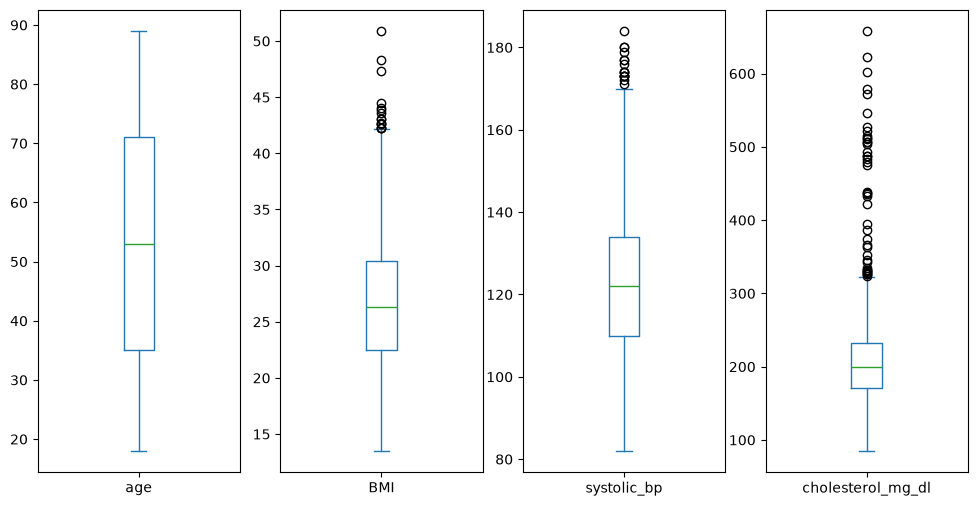

In [23]:
df_med[['age', 'BMI', 'systolic_bp', 'cholesterol_mg_dl']].plot(kind='box', subplots=True, figsize=(12, 6))

fasting_glucose_mg_dl       Axes(0.125,0.11;0.168478x0.77)
symptom_score            Axes(0.327174,0.11;0.168478x0.77)
CRP_mg_L                 Axes(0.529348,0.11;0.168478x0.77)
WBC_10e9_L               Axes(0.731522,0.11;0.168478x0.77)
dtype: object

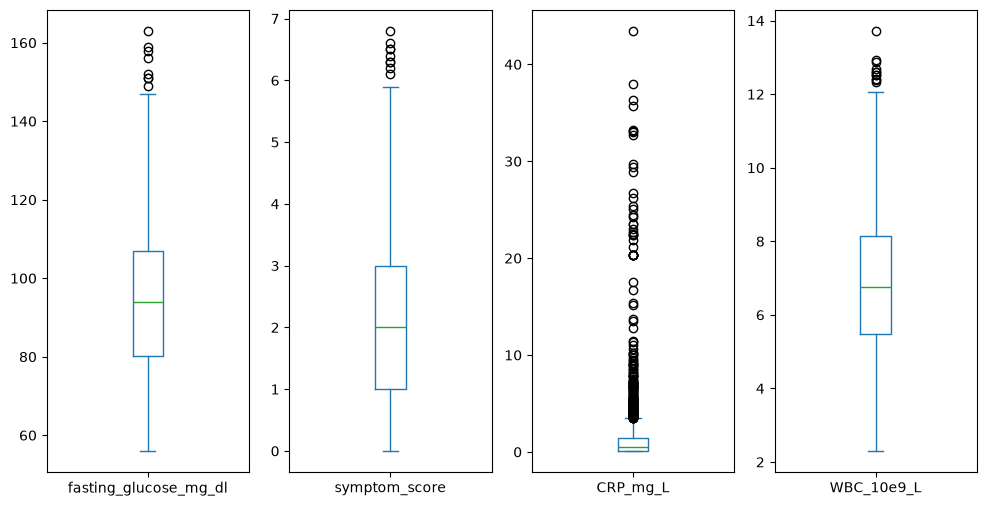

In [24]:
df_med[['fasting_glucose_mg_dl', 'symptom_score', 'CRP_mg_L', 'WBC_10e9_L']].plot(kind='box', subplots=True, figsize=(12, 6))

По боксплотам в ряде признаков (особенно cholesterol_mg_dl и CRP_mg_L) наблюдаются значения далеко за пределами усов. Учитывая медицинскую природу данных, эти значения не являются ошибками измерения, а отражают реальное состояние больных пациентов (повышенный холестерин, воспалительный процесс и т.д.).   
Для дальнейшей работы с данными было решено привести все названия полей к единому виду:

In [25]:
df_med = df_med.rename(columns={'Disease':'disease', 'ECG_result':'ecg_result', 'WBC_10e9_L':'wbc_10e9_l', 'CRP_mg_L':'crp_mg_l', 'BMI':'bmi'})
df_med.columns

Index(['age', 'sex', 'bmi', 'systolic_bp', 'cholesterol_mg_dl',
       'fasting_glucose_mg_dl', 'smoking_status', 'family_history',
       'activity_level', 'symptom_score', 'crp_mg_l', 'wbc_10e9_l',
       'ecg_result', 'disease'],
      dtype='str')

#### 2.2 Кодирование категориальных признаков


Для полей `sex`, `family_history` используется прямое (бинарное) кодирование, а для `smoking_status`, `activity_level` - порядковое, поскольку их значения имеют естественную субординацию. Значения поля `ECG_result` `ST-T abnormality` и `LVH` описывают разные явления, а не степени одного процесса, их нельзя упорядочить. Здесь уместно применить прямое кодирование с использованием дамми-переменных. Во избежание вырождения матрицы признаков удаляется один базовый столбец, поэтому будет создано только 2 новых поля. 

In [26]:
from sklearn.preprocessing import OrdinalEncoder

# бинарные признаки — простая замена на 0-1
df_med['sex'] = df_med['sex'].map({'Female': 0, 'Male': 1})
df_med['family_history'] = df_med['family_history'].map({'No': 0, 'Yes': 1})

# порядковое кодирования для признаков с субординацией
# smoking_status: Never < Former < Current
smoking_order = [['Never', 'Former', 'Current']]
encoder_smoking = OrdinalEncoder(categories=smoking_order)
df_med['smoking_status'] = encoder_smoking.fit_transform(df_med[['smoking_status']]).astype(int)

# activity_level: Low < Moderate < High
activity_order = [['Low', 'Moderate', 'High']]
encoder_activity = OrdinalEncoder(categories=activity_order)
df_med['activity_level'] = encoder_activity.fit_transform(df_med[['activity_level']]).astype(int)

# прямое кодирование для номинальных признаков
df_med = pd.get_dummies(
    df_med,
    columns=['ecg_result'],
    drop_first=True,          # удаляем один столбец, чтобы избежать мультиколлинеарности
    dtype=int                 # чтобы были 0/1, а не True/False
)

# Проверка
display(df_med.head())
print(df_med.dtypes)

,age,sex,bmi,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,smoking_status,family_history,activity_level,symptom_score,crp_mg_l,wbc_10e9_l,disease,ecg_result_Normal,ecg_result_ST-T abnormality
0,34,1,16.8,132.0,196.0,78.0,2,0,2,0.2,0.58,8.60,0,1,0
1,24,0,29.2,118.0,182.0,96.0,2,0,1,3.2,2.72,6.54,0,1,0
2,19,0,16.5,121.0,268.0,101.0,2,0,1,3.8,0.18,6.61,0,1,0
3,89,0,15.4,117.0,136.0,96.0,0,0,0,2.6,1.83,5.67,0,1,0
4,66,1,16.7,82.0,241.0,126.0,1,0,1,3.5,1.16,2.66,0,1,0


age                              int64
sex                              int64
bmi                            float64
systolic_bp                    float64
cholesterol_mg_dl              float64
fasting_glucose_mg_dl          float64
smoking_status                   int64
family_history                   int64
activity_level                   int64
symptom_score                  float64
crp_mg_l                       float64
wbc_10e9_l                     float64
disease                          int64
ecg_result_Normal                int64
ecg_result_ST-T abnormality      int64
dtype: object


#### 2.3 Матрица диаграмм рассеивания

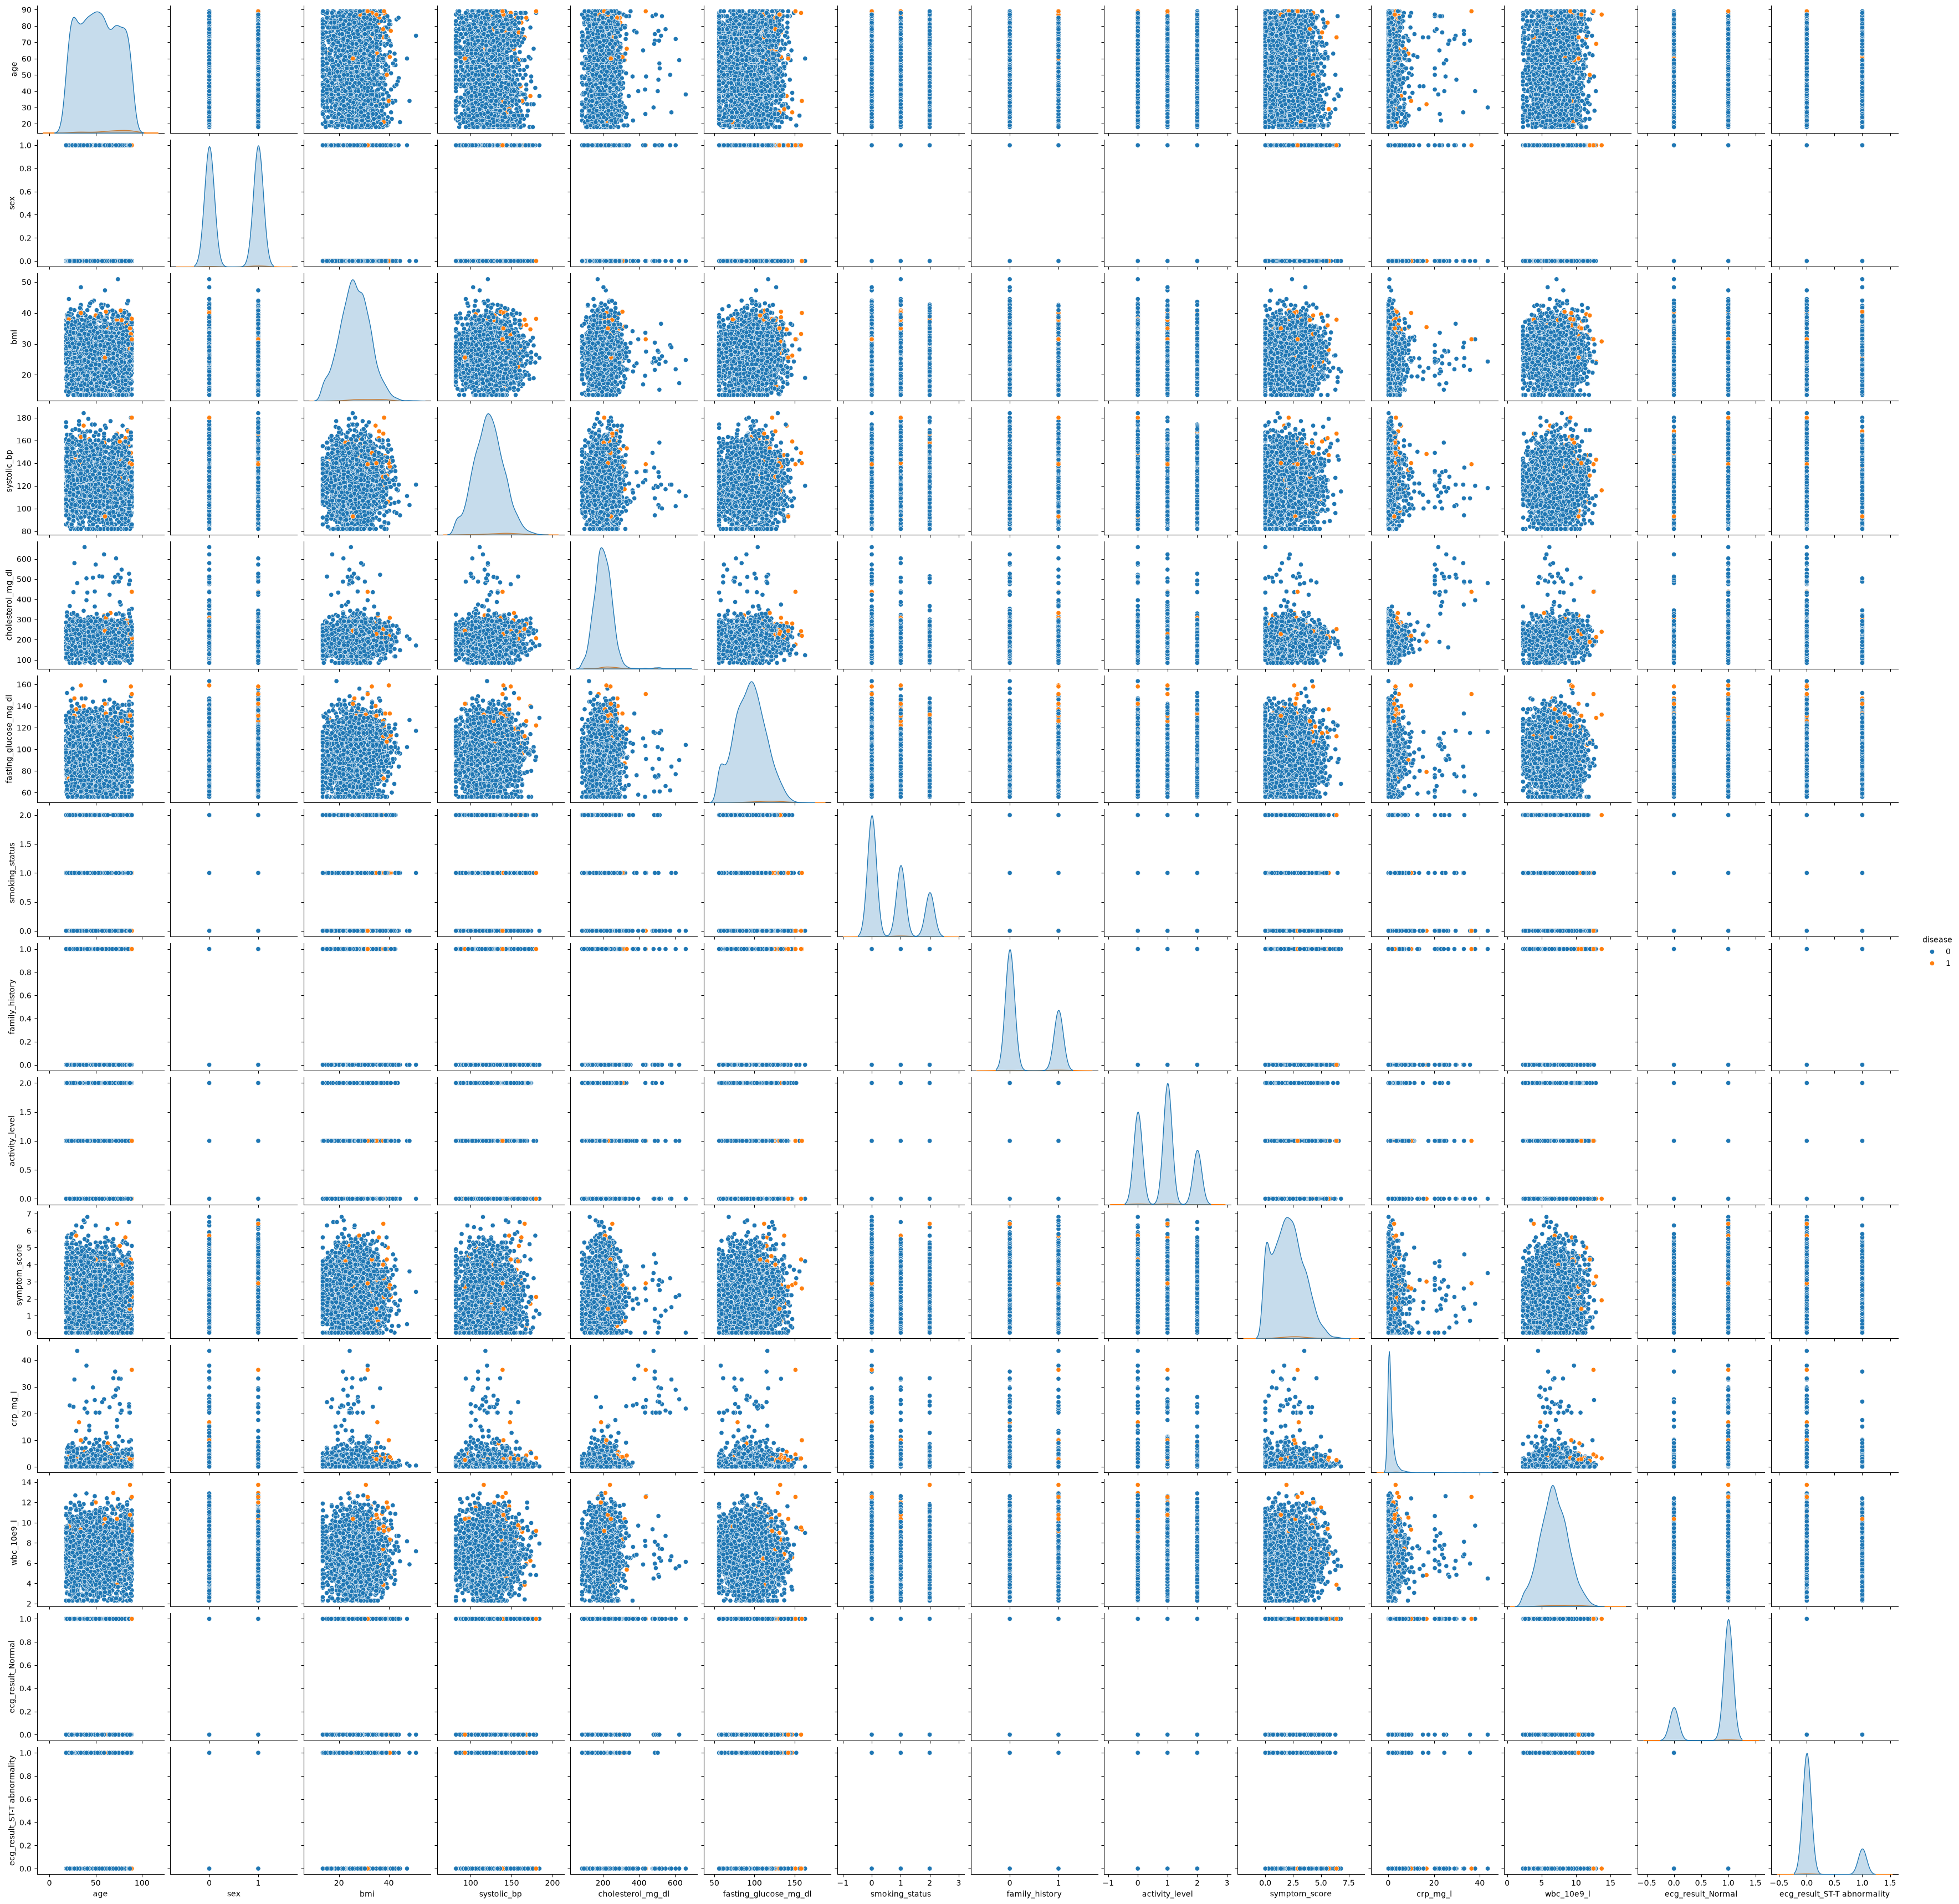

In [27]:
import seaborn as sns

sns.pairplot(df_med, hue = 'disease')

# sns.scatterplot(data = df_med, x='age', y='cholesterol_mg_dl', hue = 'disease')
# sns.scatterplot(data = df_med, x='crp_mg_l', y='symptom_score', hue = 'disease') 
# sns.scatterplot(data = df_med, x='symptom_score', y='age', hue = 'disease') 
# sns.scatterplot(data = df_med, x='age', y='smoking_status', hue = 'disease') 
# sns.scatterplot(data = df_med, x='age', y='ecg_result_Normal', hue = 'disease') 

Соотношение диагнозов болен/не_болен 2981 : 49 соответственно. Поэтому на scatter-графиках оранжевые точки всегда будут выглядеть редкими, даже если признак хорошо связан с болезнью. Судить только по «густоте» оранжевых точек нельзя. По графикам можно сделать промежуточные выводы:
- Высокие значения холестерина (>400) встречаются и у здоровых, и у больных всех возрастов.
- Больные разбросаны по всему диапазону возраста и симптоматики. Нет чёткой зоны, где оранжевые точки концентрируются.
- Почти все пациенты (и больные, и здоровые) имеют ecg_result_Normal = 1. Аномалии ЭКГ редки в обоих классах.

Визуально ни один признак не показывает чёткого разделения больных и здоровых. Наиболее заметные тенденции (пожилой возраст, повышенный BMI) прослеживаются, но подтверждать их нужно с помощью метрик качества кластеризации.

#### 2.4 Кластеризация методом k-means
Прежде чем приступать к кластеризации, необходимо выделить целевую переменную. 

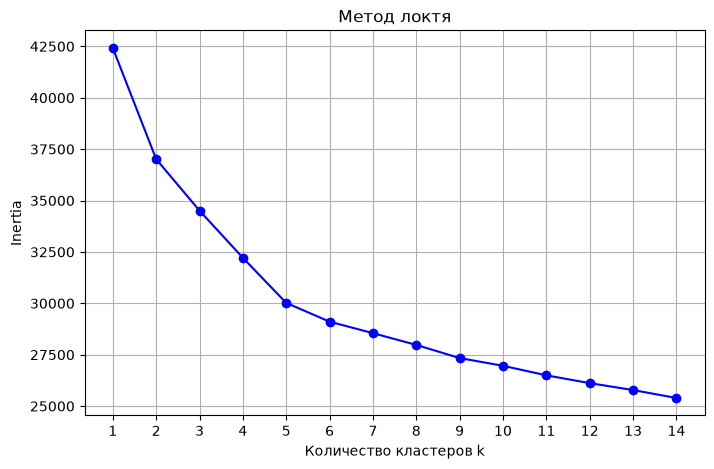

In [28]:
y_med = df_med['disease']    # целевая переменная - болен ли пациент
X_med = df_med.drop('disease', axis=1)

scaler_med = StandardScaler()
X_scaled_med = scaler_med.fit_transform(X_med)

# определение оптимального количества кластеров методом локтя
inertias = []
K_range = range(1, 15)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=15, n_init=10) # запущен 10 раз с разными случайными начальными центрами кластеров, а затем выберет результат с наименьшей inertia.
    kmeans.fit(X_scaled_med)
    inertias.append(kmeans.inertia_) # сумма квадратов расстояний от объекта до ближайшего центроида

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Количество кластеров k')
plt.ylabel('Inertia')
plt.title('Метод локтя')
plt.grid(True)
plt.xticks(K_range)
plt.show()

На графике прослеживается резкое падение inertia для k=1 до k=5, после значения k=5 снижение становится более плавным. Дальнейшее увеличение числа кластеров даёт лишь незначительный выигрыш. Поэтому в качестве оптимального количества кластеров выбрано **k = 5**.

In [29]:
k_means_med = KMeans(n_clusters=5, random_state=15)
clusters_med = k_means_med.fit_predict(X_scaled_med) # формирование вектора с метками кластеров

Чтобы определить объекты, относящиеся к одному кластеру, удобно к исходному датафрейму метки кластеров.

In [30]:
df_med['cluster'] = clusters_med
print(df_med['cluster'].value_counts().sort_index())

cluster
0    528
1    821
2     33
3    832
4    816
Name: count, dtype: int64


In [31]:
cluster_means = df_med.groupby('cluster').mean()
display(cluster_means)

,age,sex,bmi,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,smoking_status,family_history,activity_level,symptom_score,crp_mg_l,wbc_10e9_l,disease,ecg_result_Normal,ecg_result_ST-T abnormality
cluster,,,,,,,,,,,,,,,
0,54.257576,0.528409,26.764962,123.174242,201.888258,94.753788,0.662879,0.333333,0.816288,2.057386,1.072348,6.796080,0.017045,0.000000,1.000000
1,51.605359,0.000000,26.487089,121.489647,200.343484,94.289890,0.677223,0.000000,0.861145,2.047259,1.125603,6.846078,0.009744,0.957369,0.000000
2,62.030303,0.454545,24.966667,120.060606,461.369697,89.969697,0.575758,0.393939,0.727273,2.075758,26.315303,7.229697,0.030303,0.787879,0.090909
3,53.396635,0.500000,26.497716,122.811298,198.764423,94.979567,0.683894,1.000000,0.879808,2.028486,1.141298,6.845565,0.027644,0.950721,0.000000
4,53.480392,1.000000,26.277941,122.542892,199.025735,93.748775,0.691176,0.000000,0.854167,2.032598,1.043321,6.778431,0.009804,0.953431,0.000000


Выводы по кластерам:   
**Кластер 0** (528 чел.)   
Пациенты среднего возраста (~54 года), примерно поровну мужчин и женщин.
Отличительная черта — **все имеют аномалию ЭКГ типа ST-T** (ecg_result_ST-T abnormality = 1).
Остальные показатели (BMI, давление, холестерин, CRP) близки к средним по выборке. Доля больных небольшая (~1,7 %).   

**Кластер 1** (821 чел.)   
Только **женщины**. Средний возраст ~52 года. Полностью **отсутствует наследственность** по заболеванию (family_history = 0), преимущественно нормальная ЭКГ. Показатели здоровья близки к средним, доля больных низкая (~0,97 %).   

**Кластер 2** (33 чел.) — самый маленький. Самый высокий средний возраст (~62 года), **очень высокий холестерин** (≈461 против ~200 в остальных), резко **повышенный CRP** (≈26 против ~1).
Чуть более низкая физическая активность, в основном нормальная ЭКГ. Это группа пациентов с выраженными отклонениями в показателях (высокий холестерин + сильное воспаление).   

**Кластер 3** (832 чел.)
Средний возраст ~53 года, примерно поровну мужчин и женщин. Все **имеют наследственность** по заболеванию (family_history = 1).В остальном показатели близки к средним, преимущественно нормальная ЭКГ.   

**Кластер 4** (816 чел.)
Только **мужчины**. Средний возраст ~53 года. Полностью **отсутствует наследственность**, преимущественно нормальная ЭКГ. По лабораторным показателям почти не отличается от кластера 1.   

Алгоритм в основном разделил пациентов по полу (кластеры 1 и 4) и по наличию наследственности (кластер 3), а также выделил небольшую группу с выраженными лабораторными отклонениями (кластер 2) и группу с аномалиями ЭКГ (кластер 0).

#### 2.5 Вычисление метрик качества кластеризации
Чтобы понять, насколько кластеры компактны и разделены, не имея априорного разделения на классы, используется уже известная **внутренняя** метрика - коэффициент силуэта. Он принимает значения в диапазоне (-1; 1) и показывает, насколько объект похож на другие объекты своего кластера.    
Силуэт объекта $i$ вычисляется по формуле:$$S_i = \frac{b_i - a_i}{\max(a_i, b_i)},$$где
$a_i$ — среднее расстояние между объектом $i$ и другими объектами того же кластера;
$b_i$ — наименьшее среднее расстояние между объектом $i$ и объектами всех других кластеров.   
Силуэт выборки — средняя величина силуэта объектов данной выборки.

In [32]:
sil = silhouette_score(X_scaled_med, clusters_med)
print(f"Silhouette: {sil:.4f}")

Silhouette: 0.1053


Полученное значение силуэта выборки ~0.1 указывает на перекрывающиеся кластеры. В пространстве признаков данные не образуют чётких, хорошо отделённых групп. Это согласуется с диаграммами рассеивания - больные не образуют явного плотного облака точек.
   
**Внешние метрики** ARI, AMI, FMI показывают, насколько полученное разбиение совпадает с известными классами (disease). Поскольку наблюдается сильный дисбаланс классов (≈2 % больных), внешние метрики невысокие. 

In [33]:
from sklearn.metrics import (
    adjusted_rand_score,
    adjusted_mutual_info_score,
    fowlkes_mallows_score
)

ari = adjusted_rand_score(y_med, clusters_med)
ami = adjusted_mutual_info_score(y_med, clusters_med)
fmi = fowlkes_mallows_score(y_med, clusters_med)

print(f"ARI:        {ari:.4f}")
print(f"AMI:        {ami:.4f}")
print(f"FMI:        {fmi:.4f}")

ARI:        0.0003
AMI:        0.0015
FMI:        0.4937


Метрика ARI (Adjusted Rand Index) принимает значения в диапазоне (-1; 1) и измеряет сходство полученного разбиения с истинной разметкой, игнорируя перестановки. Полученное значение 0.0003 ≈ 0 означает случайный уровень совпадения (практически нет согласия с истинной меткой disease).   
Метрика AMI (Adjusted Mutual Information) принимает значения в диапазоне (0; 1) и измеряет согласованность двух назначений. По сути она сравнивает два вероятностных распределения меток кластеров, вычисляется с использованием функции энтропии (менее чувствительна к размерам кластеров, чем ARI). Полученное значение 0.0015 ≈ 0 означает случайный уровень совпадения (практически нет согласия с истинной меткой disease).   
Метрика FMI (индекс Фаулкса-Мэллоуса) принимает значения в диапазоне (0; 1) и определяет сходства между кластерами. Полученное значение 0.4937 ≈ 0.5, что при сильном дисбалансе обычно соответствует случайному угадыванию.   
Внешние метрики (ARI ≈ 0.0003, AMI ≈ 0.0015, FMI ≈ 0.494) близки к значениям, соответствующим случайному разбиению. Это объясняется сильным дисбалансом классов (около 2 % больных) и тем, что кластеризация проводилась без использования целевой переменной. Полученные кластеры отражают другие закономерности в данных (пол, наследственность, лабораторные отклонения), а не напрямую диагноз.

#### 2.6 Кластеризация иерархическим агломеративным методом
Иерархическая кластеризация представляет собой процесс иерархического построения дерева кластеров с использованием различных методов объединения или разделения кластеров. В результате получается дерево (дендрограмма), которое позволяет анализировать иерархическую структуру данных и определять кластеры на разных уровнях иерархии.   
Принцип объединения объектов в кластеры: если задана функция расстояния, можно вычислить матрицу расстояний между всеми объектами. В этой матрице каждая ячейка содержит попарное расстояние между двумя объектами. Используя эту матрицу, можно последовательно объединить близкие кластеры. Изначально **количество кластеров равно количеству точек данных**. Затем на каждом шаге **объединяются два ближайших друг к другу кластера**. На каждом шаге алгоритм наращивает кластеры с помощью присоединения соседних.   
Если нет каких-то специализированных условий, то **число кластеров можно выбирать по резкому скачку дендрограммы**. По оси y дендрограммы откладывается кластерное расстояние. Длина каждой ветви показывает, **насколько далеко друг от друга находятся объединённые кластеры**.

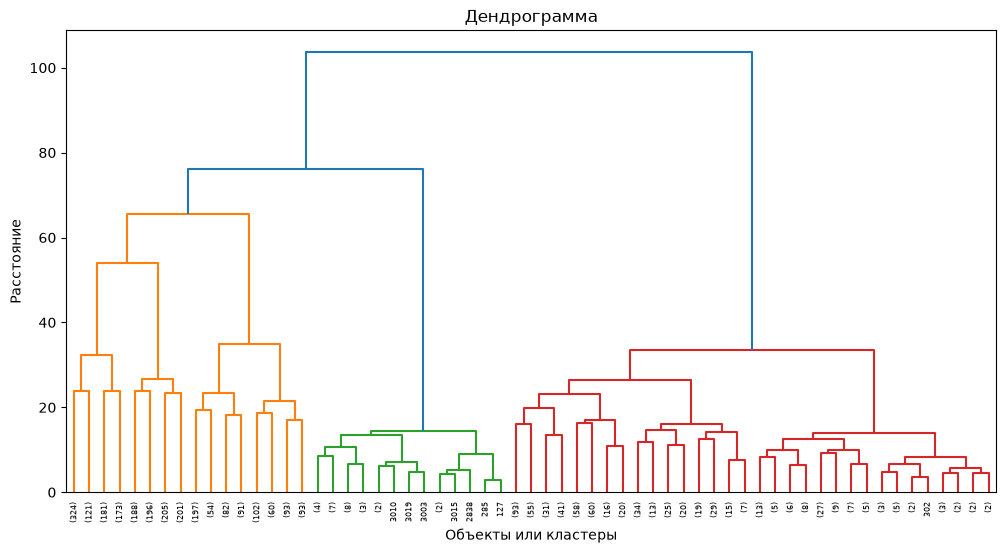

In [34]:
from scipy.cluster.hierarchy import dendrogram, linkage

# X_scaled_med стандартизированные данные

# история объединения кластеров
linked = linkage(X_scaled_med, method='ward', metric='euclidean')

# Дендрограмма
plt.figure(figsize=(12, 6))
dendrogram(
    linked,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=True,
    truncate_mode='level',   # можно убрать, если хотите полное дерево
    p=5                       # показывать только верхние уровни
)
plt.title('Дендрограмма')
plt.xlabel('Объекты или кластеры')
plt.ylabel('Расстояние')
plt.grid(False)
plt.show()

Интерпретация   
- Самый большой скачок — около y ≈ 80. Если провести горизонтальную линию чуть ниже этого узла, получится 3 кластера.
- Следующий заметный скачок — около y ≈ 65. Линия на этом уровне даёт 4 кластерf.
- Более низкие объединения происходят с меньшими скачками, поэтому делить дальше обычно нецелесообразно.

Наиболее выраженные скачки заканчиваются на переходе 4 -> 3. Поэтому разумные варианты — 3 или 4 кластера. В качестве компромиссного варианта с предыдущим анализов для дальнейшей работы **выбрано 4 кластера**.

`AgglomerativeClustering` из `sklearn.cluster` выполняет иерархическую кластеризацию с использованием подхода снизу вверх: каждый объект изначально образует собственный отдельный кластер, и кластеры последовательно объединяются вместе. В этом методе можно настраивать параметры:
- n_clusters — количество кластеров (по умолчанию 2);
- metric — метрика для вычисления связи (например, евклидово расстояние);
- linkage — критерий связи (ward минимизирует дисперсию объединяемых кластеров, average объединяет два кластера с наименьшим средним расстоянием, complete объединяет кластеры по наименьшему расстоянию между самыми удалёнными точками);
- distance_threshold — пороговое расстояние, при котором кластеры не будут объединены. 

In [35]:
from sklearn.cluster import AgglomerativeClustering

agg_4 = AgglomerativeClustering(n_clusters=4, linkage='ward')
clusters_agg_4 = agg_4.fit_predict(X_scaled_med)

df_med['cluster_agg'] = clusters_agg_4
print(df_med['cluster_agg'].value_counts().sort_index())

cluster_agg
0    1589
1     772
2      33
3     636
Name: count, dtype: int64


In [36]:
cluster_means_agg = df_med.groupby('cluster_agg').mean()
display(cluster_means_agg)

,age,sex,bmi,systolic_bp,cholesterol_mg_dl,fasting_glucose_mg_dl,smoking_status,family_history,activity_level,symptom_score,crp_mg_l,wbc_10e9_l,disease,ecg_result_Normal,ecg_result_ST-T abnormality,cluster
cluster_agg,,,,,,,,,,,,,,,,
0,52.093770,0.494021,26.369163,122.451857,199.103210,94.335431,0.685337,0.023285,0.857772,2.047766,1.125853,6.819025,0.011957,0.998741,0.000000,2.513531
1,54.062176,0.507772,26.587306,121.426166,199.129534,94.393782,0.690415,0.981865,0.880829,2.033031,1.035466,6.801477,0.025907,0.993523,0.000000,2.967617
2,61.666667,0.424242,24.884848,121.393939,461.884848,89.939394,0.606061,0.424242,0.696970,2.093939,26.170152,7.247879,0.030303,0.818182,0.060606,2.030303
3,54.372642,0.526730,26.640566,123.572327,202.415094,94.644654,0.654088,0.333333,0.825472,2.027358,1.112673,6.837893,0.014151,0.000000,0.831761,0.463836


Краткая характеристика полученных кластеров:   
**Кластер 0** (1589 чел.)
Самый крупный. Средний возраст ~52 года, примерно поровну мужчин и женщин. Все показатели близки к общим средним по выборке: нормальный холестерин (~199), низкий CRP (~1.1), подавляющее большинство объектов имеет нормальную ЭКГ. Доля больных небольшая.   
**Кластер 1** (772 чел.)
Средний возраст ~54 года. Отличительная черта — **очень высокая доля наследственности** (family_history ≈ 0.98).В остальном показатели почти такие же, как в кластере 0.   
**Кластер 2** (33 чел.) Тот же маленький кластер, что и при разбиении k-means (k=5): самый высокий возраст (~62 года), очень высокий холестерин (~462), резко повышенный CRP (~26), чуть ниже активность.   
**Кластер 3** (636 чел.) Средний возраст ~54 года. Отличительная черта — **все имеют аномалию ЭКГ , в основном типа ST-T** (ecg_result_Normal = 0, ecg_result_ST-T abnormality ≈ 0.83).Остальные показатели близки к средним.   

Большой кластер 0 — это обычные пациенты со средними показателями без особенностей. Структура получилась интерпретируемой и похожей на то, что раньше давал k-means.

#### 2.7 Сравнение качества кластеризации иерархическим агломеративным методом и методом k-means

In [37]:
kmeans_4 = KMeans(n_clusters=4, random_state=15, n_init=10)
clusters_kmeans_4 = kmeans_4.fit_predict(X_scaled_med)

In [38]:
print("_____________________Метрики KMeans (k=4)________________________")
print(f"Silhouette: {silhouette_score(X_scaled_med, clusters_kmeans_4):.4f}")
print(f"ARI:        {adjusted_rand_score(y_med, clusters_kmeans_4):.4f}")
print(f"AMI:        {adjusted_mutual_info_score(y_med, clusters_kmeans_4):.4f}")
print(f"FMI:        {fowlkes_mallows_score(y_med, clusters_kmeans_4):.4f}")

_____________________Метрики KMeans (k=4)________________________
Silhouette: 0.0996
ARI:        0.0036
AMI:        0.0000
FMI:        0.6227


In [39]:
print("\n_____________________Метрики AgglomerativeClustering (k=4, ward)________________________")
print(f"Silhouette: {silhouette_score(X_scaled_med, clusters_agg_4):.4f}")
print(f"ARI:        {adjusted_rand_score(y_med, clusters_agg_4):.4f}")
print(f"AMI:        {adjusted_mutual_info_score(y_med, clusters_agg_4):.4f}")
print(f"FMI:        {fowlkes_mallows_score(y_med, clusters_agg_4):.4f}")


_____________________Метрики AgglomerativeClustering (k=4, ward)________________________
Silhouette: 0.1078
ARI:        0.0040
AMI:        0.0009
FMI:        0.6116


По внутренней метрике (силуэт) и по двум внешним (ARI, AMI) немного лучше сработал агломеративный метод. В целом разница между методами очень небольшая. Оба дают **слабое разделение** (силуэт ≈ 0.10) и почти не совпадают с истинной меткой disease (ARI и AMI близки к нулю). Это ожидаемо из-за сильного **дисбаланса классов** и отсутствия кластерной структуры в данных.

 ### Вывод
В ходе выполнения работы была выполнена кластеризация пациентов по медицинским признакам двумя методами: KMeans и агломеративной иерархической кластеризацией.   
Основные результаты:
- Данные имеют слабую кластерную структуру. Коэффициент силуэта для обоих методов оказался низким (≈ 0.10), что говорит о перекрывающихся и в общем не компактных группах.
- Внешние метрики (ARI, AMI) близки к нулю из-за сильного дисбаланса классов (≈ 2 % больных). Кластеры отражают не диагноз, а другие закономерности: пол, наличие наследственности, аномалии ЭКГ и отклонения в анализах.
- Оба метода устойчиво выделяют одну и ту же небольшую группу пациентов (33 человека) с резко повышенным холестерином и CRP.

При одинаковом числе кластеров (k=4) агломеративный метод показал незначительно лучший силуэт и чуть более высокие ARI/AMI. Для данной задачи предпочтительнее агломеративная иерархическая кластеризация (с критерием Ward). Она дала чуть более высокое качество по большинству метрик, а также позволила наглядно проанализировать структуру данных с помощью дендрограммы и обоснованно выбрать число кластеров. Также данный метод хорошо выделил интерпретируемые группы (по наследственности, ЭКГ и отклонениям в анализах крови).